#**Base de Dados - Geração Fotovoltaica**

**PVGIS - Photovoltaic Geographical Information Systems**

- Base de Dados do PVGIS para obtenção dos dados meteológicos históricos e contrução de perfis de gração PV.

**Localidade: Zurich, Suiça**

- Informações de radiação solar, meteorologia e estimativas de desempenho de distemas fotovoltaicos

#**Inicialização**

In [6]:
!pip install pvlib

In [7]:
import pvlib
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt

# **Dados Metreológicos históricos**

- Utilização da biblioteca .pvlib, modulo iotools, para acessar os dados históricos do PVGIS

- Irradiação Solar(global, direta normal e difusa horizontal), Temperatura do Ar e Velocidade do Vento

In [10]:
# Localização: Zürich/Kloten, Suíça
latitude = 47.4796
longitude = 8.5360

# Definição dos parâmetros dos módulos solares
surface_tilt = 30
surface_azimuth = 180

# Período histórico
start_year = 2022
end_year = 2023

**Obtenção dos Dados Metereológicos**

In [11]:
weather, metadata = pvlib.iotools.get_pvgis_hourly(
    latitude=latitude,
    longitude=longitude,
    start=start_year,
    end=end_year,
    surface_tilt=surface_tilt,
    surface_azimuth=surface_azimuth,
    usehorizon=True,
    map_variables=True)

print(weather.head())

                           poa_direct  poa_sky_diffuse  poa_ground_diffuse  \
time                                                                         
2022-01-01 00:10:00+00:00         0.0              0.0                 0.0   
2022-01-01 01:10:00+00:00         0.0              0.0                 0.0   
2022-01-01 02:10:00+00:00         0.0              0.0                 0.0   
2022-01-01 03:10:00+00:00         0.0              0.0                 0.0   
2022-01-01 04:10:00+00:00         0.0              0.0                 0.0   

                           solar_elevation  temp_air  wind_speed  Int  
time                                                                   
2022-01-01 00:10:00+00:00              0.0      3.65        1.10    0  
2022-01-01 01:10:00+00:00              0.0      3.74        0.69    0  
2022-01-01 02:10:00+00:00              0.0      3.49        0.41    0  
2022-01-01 03:10:00+00:00              0.0      2.89        0.62    0  
2022-01-01 04:10:00+0

In [12]:
print("Colunas disponíveis:")
print(weather.columns.tolist())

print("\nPrimeiras linhas:")
display(weather.head())

print("\nÚltimas linhas:")
display(weather.tail())

print("\nPeríodo dos dados:")
print(weather.index.min(), "até", weather.index.max())

print("\nQuantidade de registros:")
print(len(weather))

Colunas disponíveis:
['poa_direct', 'poa_sky_diffuse', 'poa_ground_diffuse', 'solar_elevation', 'temp_air', 'wind_speed', 'Int']

Primeiras linhas:


,poa_direct,poa_sky_diffuse,poa_ground_diffuse,solar_elevation,temp_air,wind_speed,Int
time,,,,,,,
2022-01-01 00:10:00+00:00,0.0,0.0,0.0,0.0,3.65,1.10,0
2022-01-01 01:10:00+00:00,0.0,0.0,0.0,0.0,3.74,0.69,0
2022-01-01 02:10:00+00:00,0.0,0.0,0.0,0.0,3.49,0.41,0
2022-01-01 03:10:00+00:00,0.0,0.0,0.0,0.0,2.89,0.62,0
2022-01-01 04:10:00+00:00,0.0,0.0,0.0,0.0,2.70,0.76,0



Últimas linhas:


,poa_direct,poa_sky_diffuse,poa_ground_diffuse,solar_elevation,temp_air,wind_speed,Int
time,,,,,,,
2023-12-31 19:10:00+00:00,0.0,0.0,0.0,0.0,2.44,1.52,0
2023-12-31 20:10:00+00:00,0.0,0.0,0.0,0.0,2.06,1.52,0
2023-12-31 21:10:00+00:00,0.0,0.0,0.0,0.0,0.95,1.52,0
2023-12-31 22:10:00+00:00,0.0,0.0,0.0,0.0,-0.33,1.59,0
2023-12-31 23:10:00+00:00,0.0,0.0,0.0,0.0,-1.15,1.79,0



Período dos dados:
2022-01-01 00:10:00+00:00 até 2023-12-31 23:10:00+00:00

Quantidade de registros:
17520


#**Preparação e Validação dos Dados**

In [13]:
# Quantidade de registros por ano
print(weather.groupby(weather.index.year).size())

time
2022    8760
2023    8760
dtype: int64


In [14]:
# Verifica valores ausentes
print("Valores ausentes por coluna:")
print(weather.isnull().sum())

Valores ausentes por coluna:
poa_direct            0
poa_sky_diffuse       0
poa_ground_diffuse    0
solar_elevation       0
temp_air              0
wind_speed            0
Int                   0
dtype: int64


**Detalhes da base de dados trabalhada**
- Intervalos de 1h entre as medições
- Período completo de 2012-2014
- Infos sobre as condições ambientais em que o sistema fotovoltaico estaria submetido

In [15]:
# Estatísticas descritivas
display(weather.describe())

,poa_direct,poa_sky_diffuse,poa_ground_diffuse,solar_elevation,temp_air,wind_speed,Int
count,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.0
mean,109.918229,66.289316,2.044491,13.725022,10.808846,1.513045,0.0
std,221.128536,92.431548,3.233539,18.476061,8.091333,1.001187,0.0
min,0.000000,0.000000,0.000000,0.000000,-8.070000,0.000000,0.0
25%,0.000000,0.000000,0.000000,0.000000,4.180000,0.830000,0.0
50%,0.000000,0.000000,0.000000,0.000000,10.570000,1.310000,0.0
75%,71.430000,123.142500,2.962500,24.260000,16.970000,1.930000,0.0
max,973.350000,442.420000,13.130000,65.730000,34.030000,7.720000,0.0


## **Modelação do Sistema Fotovoltaico com PvLib**

- Potência de referência: 1kWh
- Orientação placas solares: Sul (0* PVGIS)

**Definição da irradiância global pela soma das componentes de irradiância**
- Gg = Gd + Gdf + Gr
Potência gerada depende da quantidade de radiação que incide sobre o painel

**Estimativa das temperaturas das células por meio do Modelo Térmico de Faiman da .pvlib**
- Temperatura influência no desempenho dos módulos e consequentemente na potência gerada

Tm = Ta + (Gg/(U0 + U1.v))
- Temp ambiente, Irradiância global e velocidade do vento estimam a temperatura do módulo


In [16]:
# Irradiância total no plano do painel
weather["poa_global"] = (weather["poa_direct"] +weather["poa_sky_diffuse"] +weather["poa_ground_diffuse"])

# Estimativa da temperatura das células fotovoltaicas
weather["temp_cell"] = pvlib.temperature.faiman(
    poa_global=weather["poa_global"],
    temp_air=weather["temp_air"],
    wind_speed=weather["wind_speed"]
)

# Parâmetros do sistema fotovoltaico

# Potência nominal: 1 kWp (em W)
pdc0 = 1000
# Coeficiente de temperatura (1/°C)
gamma_pdc = -0.0035

display(weather[["poa_global","temp_air","wind_speed","temp_cell"]].head(10))

,poa_global,temp_air,wind_speed,temp_cell
time,,,,
2022-01-01 00:10:00+00:00,0.00,3.65,1.10,3.650000
2022-01-01 01:10:00+00:00,0.00,3.74,0.69,3.740000
2022-01-01 02:10:00+00:00,0.00,3.49,0.41,3.490000
2022-01-01 03:10:00+00:00,0.00,2.89,0.62,2.890000
2022-01-01 04:10:00+00:00,0.00,2.70,0.76,2.700000
2022-01-01 05:10:00+00:00,0.00,3.02,0.48,3.020000
2022-01-01 06:10:00+00:00,0.00,3.18,0.21,3.180000
2022-01-01 07:10:00+00:00,0.00,2.13,0.62,2.130000
2022-01-01 08:10:00+00:00,264.50,2.00,0.55,11.196162


## **Calculo da Potência Fotovoltaica**

Criação da série temporal de potência DC para um sistema fotovoltaico de referência de 1kWp (2021-2014)
- estimativa simplificada (sem modelo de inversor) - painel horizontal
- Modelo pvwatts_dc() .pvlib - para estimar a potência elétrica DC produzida pelo sistema fotovoltaico



In [17]:
# Calcula a potência DC gerada pelo sistema fotovoltaico
weather["pv_power"] = pvlib.pvsystem.pvwatts_dc(
    effective_irradiance=weather["poa_global"],
    temp_cell=weather["temp_cell"],
    pdc0=pdc0,
    gamma_pdc=gamma_pdc
)

# Limita valores negativos a zero
weather["pv_power"] = weather["pv_power"].clip(lower=0)

display(weather[["poa_global","temp_cell","pv_power"]].head(15))

,poa_global,temp_cell,pv_power
time,,,
2022-01-01 00:10:00+00:00,0.00,3.650000,0.000000
2022-01-01 01:10:00+00:00,0.00,3.740000,0.000000
2022-01-01 02:10:00+00:00,0.00,3.490000,0.000000
2022-01-01 03:10:00+00:00,0.00,2.890000,0.000000
2022-01-01 04:10:00+00:00,0.00,2.700000,0.000000
2022-01-01 05:10:00+00:00,0.00,3.020000,0.000000
2022-01-01 06:10:00+00:00,0.00,3.180000,0.000000
2022-01-01 07:10:00+00:00,0.00,2.130000,0.000000
2022-01-01 08:10:00+00:00,264.50,11.196162,277.278903


In [18]:
# Estatísticas da potência fotovoltaica
print("Potência fotovoltaica (W):")
print(weather["pv_power"].describe())

print("\nPotência máxima (kW):")
print(weather["pv_power"].max() / 1000)

Potência fotovoltaica (W):
count    17520.000000
mean       172.167664
std        270.773820
min          0.000000
25%          0.000000
50%          0.000000
75%        249.605797
max       1102.120284
Name: pv_power, dtype: float64

Potência máxima (kW):
1.1021202841724378


# **Contrução das Curvas de Geração**

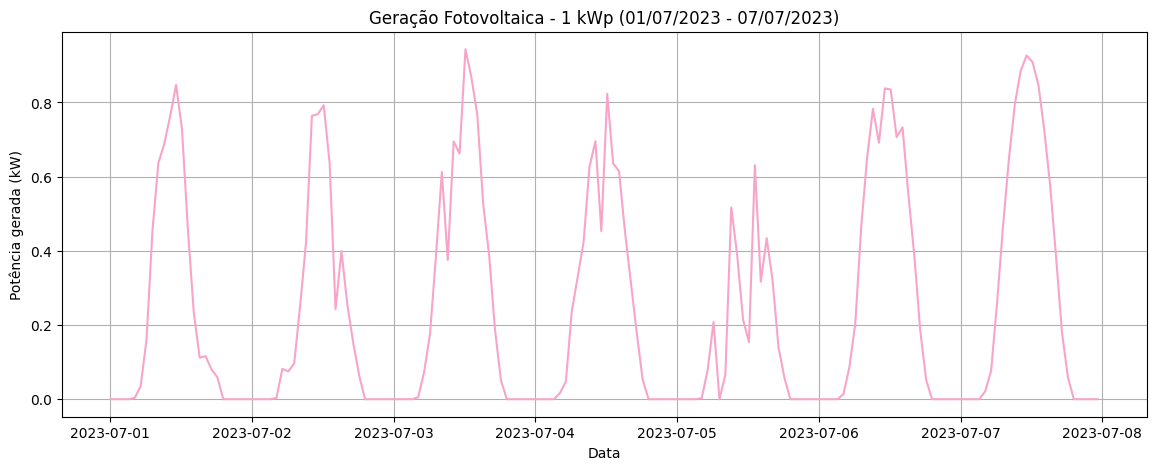

In [21]:
# Seleciona uma semana de dados 35°
weather_week = weather.loc["2023-07-01":"2023-07-07"]

plt.figure(figsize=(14, 5))

plt.plot(weather_week.index, weather_week["pv_power"] / 1000, color="#F8A4C8")

plt.xlabel("Data")
plt.ylabel("Potência gerada (kW)")
plt.title("Geração Fotovoltaica - 1 kWp (01/07/2023 - 07/07/2023)")
plt.grid()
plt.show()


### **Gráfico geração diária de Potência DC produzida pelos módulos fotovoltaicos**

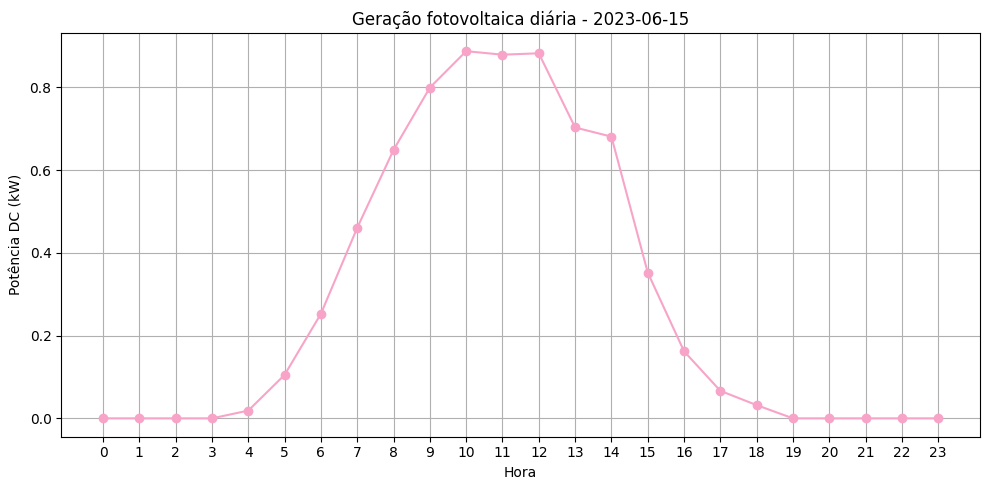

Energia diária estimada: 6.93 kWh


In [29]:
# Gáficos geração PV diários para placas com inclinação de 35°

date = "2023-06-15"
daily_data = weather[weather.index.strftime("%Y-%m-%d") == date]

if daily_data.empty:
    print("Não existem dados para essa data.")
else:
    plt.figure(figsize=(10, 5))

    # Converte potência de W para kW
    plt.plot(daily_data.index.hour,daily_data["pv_power"] / 1000,marker="o", color = "#F8A4C8")

    plt.title(f"Geração fotovoltaica diária - {date}")
    plt.xlabel("Hora")
    plt.ylabel("Potência DC (kW)")
    plt.xticks(range(0, 24))
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    daily_energy = daily_data["pv_power"].sum() / 1000

    print(f"Energia diária estimada: {daily_energy:.2f} kWh")

## **Modelagem com o Inversor Fotovoltico**

Conversar potência DC gerada para potência AC

Pac(t) = Pdc(t) . ninv

**Parâmetros do Inversor**

In [30]:
# Eficiência nominal do inversor
eta_inv_nom = 0.97

# Potência nominal AC (W)
pac0_inv = 1000

# Potência nominal de entrada DC do inversor
pdc0_inv = pac0_inv / eta_inv_nom

# Conversão DC para AC utilizando o modelo PVWatts
weather["pv_power_ac"] = pvlib.inverter.pvwatts(
    pdc=weather["pv_power"],
    pdc0=pdc0_inv,
    eta_inv_nom=eta_inv_nom)

# Limita valores negativos a zero
weather["pv_power_ac"] = weather["pv_power_ac"].clip(lower=0)

display(weather[["pv_power", "pv_power_ac"]].head(15))

,pv_power,pv_power_ac
time,,
2022-01-01 00:10:00+00:00,0.000000,0.000000
2022-01-01 01:10:00+00:00,0.000000,0.000000
2022-01-01 02:10:00+00:00,0.000000,0.000000
2022-01-01 03:10:00+00:00,0.000000,0.000000
2022-01-01 04:10:00+00:00,0.000000,0.000000
2022-01-01 05:10:00+00:00,0.000000,0.000000
2022-01-01 06:10:00+00:00,0.000000,0.000000
2022-01-01 07:10:00+00:00,0.000000,0.000000
2022-01-01 08:10:00+00:00,277.278903,267.790176


**Gráficos - Geração PV com inversores fotovoltaicos**

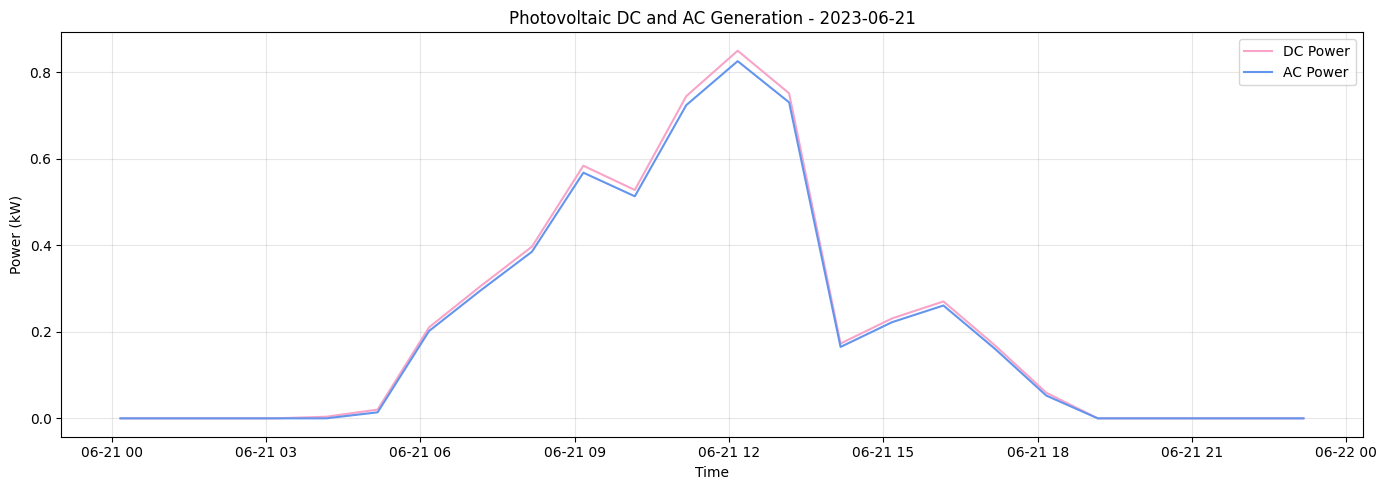

In [32]:
date = "2023-06-21"

daily_data = weather[weather.index.strftime("%Y-%m-%d") == date]
plt.figure(figsize=(14, 5))

plt.plot(daily_data.index,daily_data["pv_power"] / 1000,label="DC Power",color="#F8A4C8")
plt.plot(daily_data.index,daily_data["pv_power_ac"] / 1000,label="AC Power",color="#6495ED")

plt.xlabel("Time")
plt.ylabel("Power (kW)")
plt.title(f"Photovoltaic DC and AC Generation - {date}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

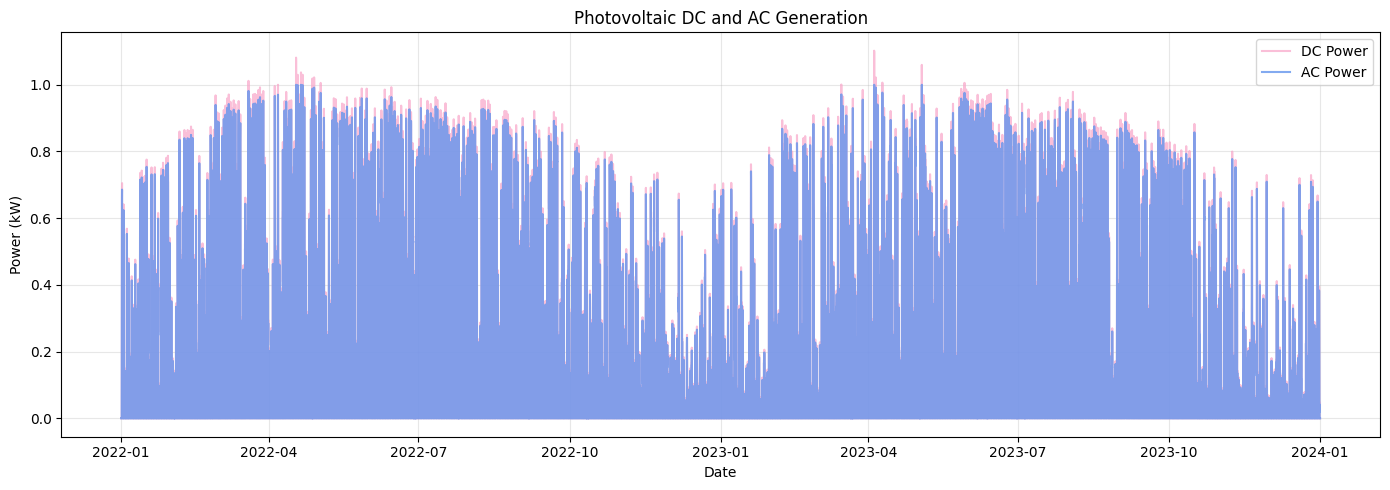

In [33]:
plt.figure(figsize=(14, 5))

plt.plot(weather.index,weather["pv_power"] / 1000,label="DC Power",color="#F8A4C8",alpha=0.7)
plt.plot(weather.index,weather["pv_power_ac"] / 1000,label="AC Power",color="#6495ED",alpha=0.8)

plt.xlabel("Date")
plt.ylabel("Power (kW)")
plt.title("Photovoltaic DC and AC Generation")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### **Normalização dos Dados**

In [34]:
# Normalização da potência fotovoltaica AC
weather["pv_power_ac_norm"] = weather["pv_power_ac"] / 1000
display(weather[["pv_power_ac", "pv_power_ac_norm"]].head(15))

,pv_power_ac,pv_power_ac_norm
time,,
2022-01-01 00:10:00+00:00,0.000000,0.000000
2022-01-01 01:10:00+00:00,0.000000,0.000000
2022-01-01 02:10:00+00:00,0.000000,0.000000
2022-01-01 03:10:00+00:00,0.000000,0.000000
2022-01-01 04:10:00+00:00,0.000000,0.000000
2022-01-01 05:10:00+00:00,0.000000,0.000000
2022-01-01 06:10:00+00:00,0.000000,0.000000
2022-01-01 07:10:00+00:00,0.000000,0.000000
2022-01-01 08:10:00+00:00,267.790176,0.267790


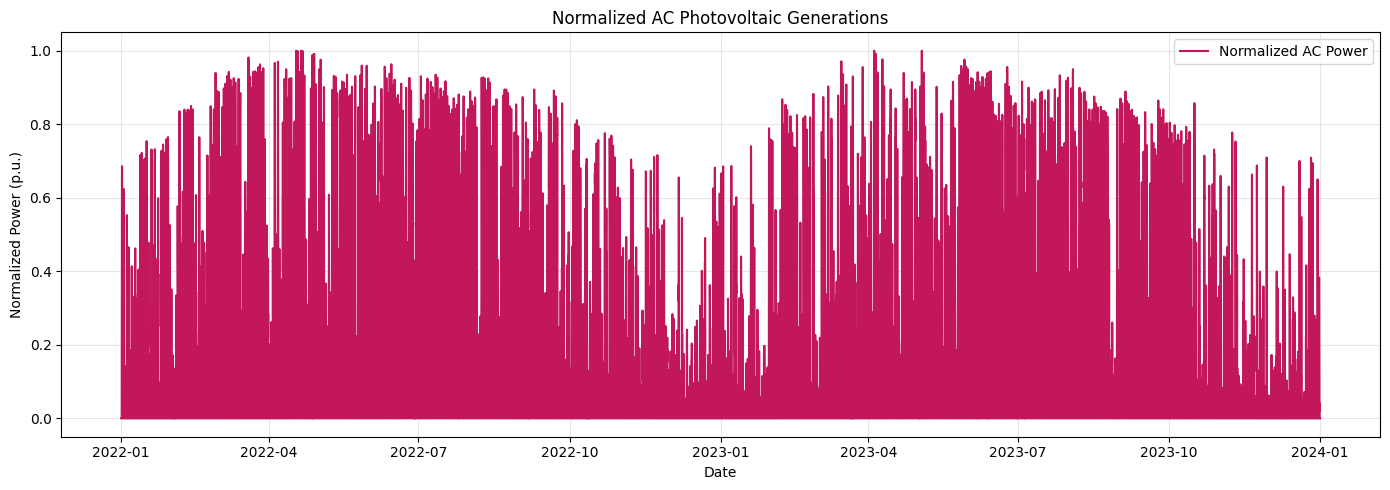

In [35]:
plt.figure(figsize=(14, 5))

plt.plot(weather.index,weather["pv_power_ac_norm"],label="Normalized AC Power",color="#C2185B")

plt.xlabel("Date")
plt.ylabel("Normalized Power (p.u.)")
plt.title("Normalized AC Photovoltaic Generations")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## **Criação Arquivos Geração PV**

**Interpolação dos dados p/ 15 minutos**

In [36]:
# Interpolação da geração PV para intervalos de 15 minutos

pv_data = weather[["pv_power_ac_norm"]].copy()

# Garantir ordenação temporal
pv_data = pv_data.sort_index()

# Ajustar o índice original para horas cheias
pv_data.index = pv_data.index - pd.Timedelta(minutes=10)

# Criar índice de 15 minutos
new_index = pd.date_range(
    start=pv_data.index.min(),
    end=pv_data.index.max(),
    freq="15min"
)

# Reindexar e interpolar
pv_data = pv_data.reindex(pv_data.index.union(new_index))
pv_data = pv_data.interpolate(method="time")

# Manter somente os horários de 15 minutos
pv_data = pv_data.loc[new_index]

# Transformar índice em coluna
pv_data = pv_data.reset_index()
pv_data = pv_data.rename(columns={"index": "datetime"})

**Série Temporal Interpolada Diária**


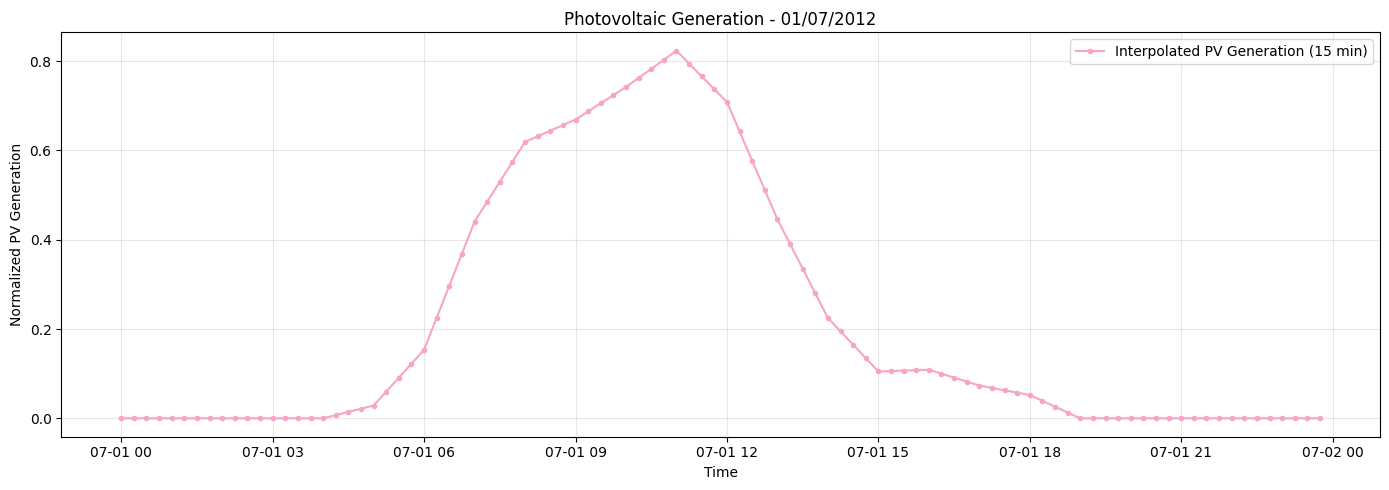

In [38]:

pv_day = pv_data.loc[
    (pv_data["datetime"] >= "2023-07-01") &
    (pv_data["datetime"] < "2023-07-02")
]

fig, axes = plt.subplots(1, 1, figsize=(14, 5))

axes.plot(pv_day["datetime"],pv_day["pv_power_ac_norm"],label="Interpolated PV Generation (15 min)",color="#F8A4C8",marker="o",markersize=3)
axes.set_xlabel("Time")
axes.set_ylabel("Normalized PV Generation")
axes.set_title("Photovoltaic Generation - 01/07/2012")
axes.grid(True, alpha=0.3)
axes.legend()

plt.tight_layout()
plt.show()

**Série Temporal Interpolada Semanal**

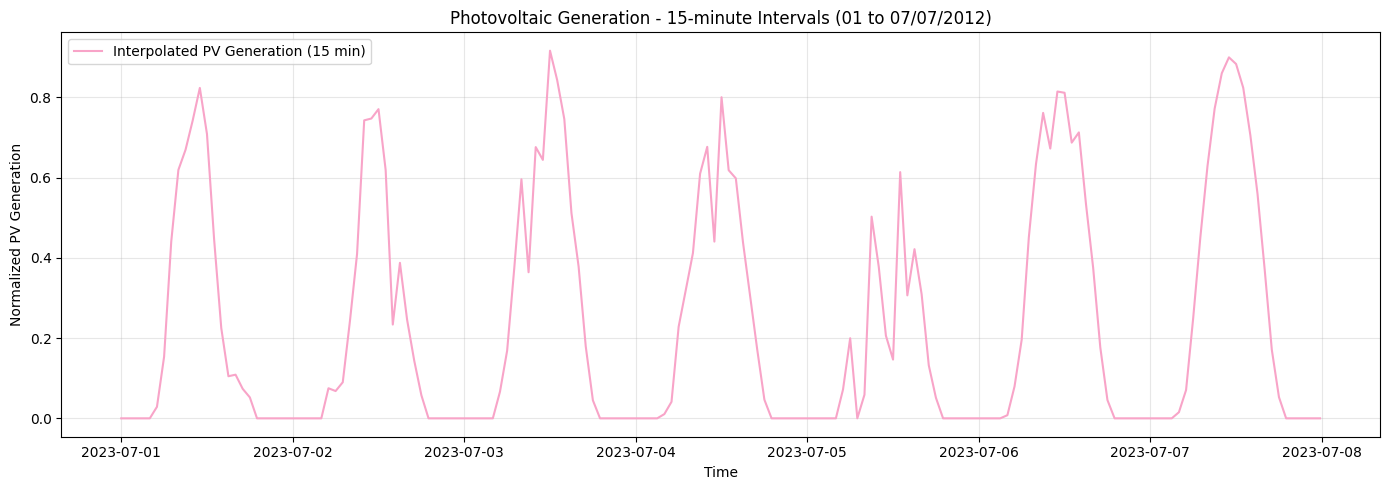

In [37]:
pv_week = pv_data.loc[
    (pv_data["datetime"] >= "2023-07-01") &
    (pv_data["datetime"] < "2023-07-08")]

fig, axes = plt.subplots(1, 1, figsize=(14, 5))

axes.plot(pv_week["datetime"],pv_week["pv_power_ac_norm"],label="Interpolated PV Generation (15 min)",color="#F8A4C8")
axes.set_xlabel("Time")
axes.set_ylabel("Normalized PV Generation")
axes.set_title("Photovoltaic Generation - 15-minute Intervals (01 to 07/07/2012)")
axes.grid(True, alpha=0.3)
axes.legend()

plt.tight_layout()
plt.show()

**Série Temporal Interpolada Completa**


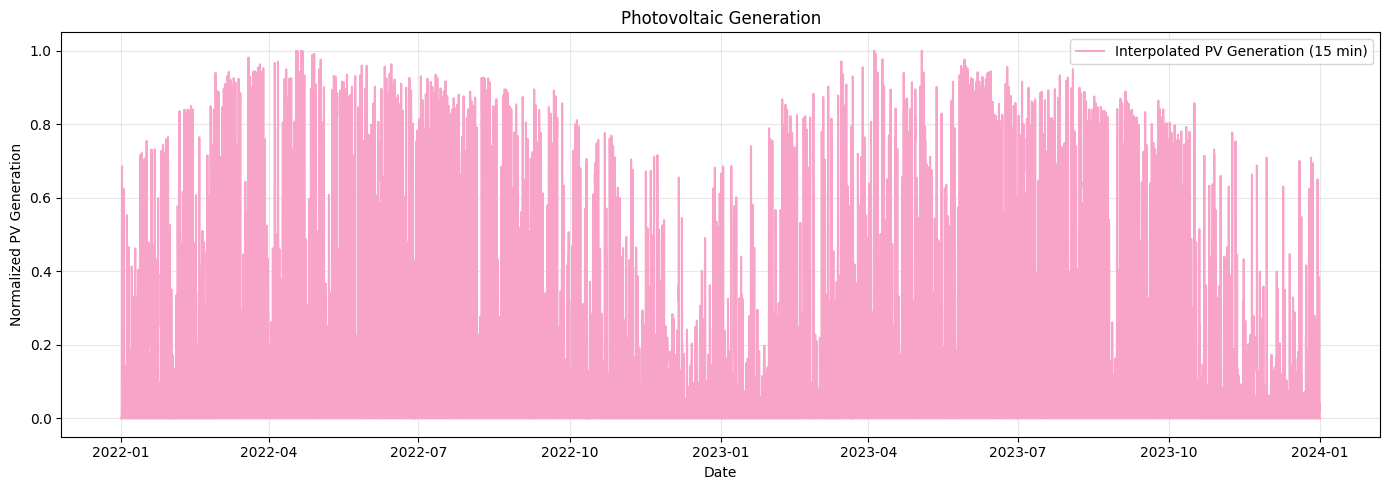

In [39]:
fig, axes = plt.subplots(1, 1, figsize=(14, 5))

axes.plot(pv_data["datetime"],pv_data["pv_power_ac_norm"],label="Interpolated PV Generation (15 min)",color="#F8A4C8")
axes.set_xlabel("Date")
axes.set_ylabel("Normalized PV Generation")
axes.set_title("Photovoltaic Generation")
axes.grid(True, alpha=0.3)
axes.legend()

plt.tight_layout()
plt.show()

**Geração do Arquivo .csv**

In [40]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [41]:
pv_data = pv_data.rename(columns={"pv_power_ac_norm": "power_kWh"})

In [42]:
import os

output_path = "/content/drive/MyDrive/IC-2026/Data_London"

file_name = "pv_generation_Switzerland.csv"

pv_data.to_csv(os.path.join(output_path, file_name), index=False)

print("Total de registros:", len(pv_data))
display(pv_data.head(10))

Total de registros: 70077


,datetime,power_kWh
0,2022-01-01 00:00:00+00:00,0.0
1,2022-01-01 00:15:00+00:00,0.0
2,2022-01-01 00:30:00+00:00,0.0
3,2022-01-01 00:45:00+00:00,0.0
4,2022-01-01 01:00:00+00:00,0.0
5,2022-01-01 01:15:00+00:00,0.0
6,2022-01-01 01:30:00+00:00,0.0
7,2022-01-01 01:45:00+00:00,0.0
8,2022-01-01 02:00:00+00:00,0.0
9,2022-01-01 02:15:00+00:00,0.0
